# Chapitre 11 - Cours 1 : transmettre des flux d'événements, les courtiers de messages

Le chapitre 10 traitait des entrées **bornées** : un job lit des fichiers de
taille connue, s'arrête, et son résultat est une donnée dérivée que l'on peut recalculer.
Mais la plupart des données arrivent au fil de l'eau et ne sont jamais « complètes » :
les utilisateurs produisaient des événements hier, en produisent aujourd'hui et en
produiront demain. Découper ce flux en lots quotidiens donne des résultats qui ont un
jour de retard ; le **traitement de flux** (stream processing) pousse l'idée à la limite
en traitant chaque événement dès qu'il arrive.

Ce premier notebook couvre le début de la section *Transmitting Event Streams* :
l'introduction, *Messaging Systems* (*Direct messaging from producers to consumers*,
*Message brokers*, *Message brokers compared to databases*, *Multiple consumers*,
*Acknowledgments and redelivery*). Le cours 2 traitera des courtiers fondés sur un
journal.

**Plan.**

1. Événements, producteurs, consommateurs : pourquoi ne pas simplement interroger une base ?
2. Les deux questions qui distinguent les systèmes de messagerie.
3. La messagerie directe et ses limites.
4. Les courtiers de messages, et ce qui les distingue d'une base de données.
5. Plusieurs consommateurs : répartition de charge et diffusion.
6. Acquittements, relivraison et réordonnancement.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import streams as st
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. Événements, producteurs, consommateurs (section *Transmitting Event Streams*)

Dans un contexte de flux, l'enregistrement de base s'appelle un **événement** : un petit
objet autonome et **immuable** qui décrit quelque chose qui s'est produit à un instant
donné (un clic, un achat, une mesure de capteur, une ligne de journal d'un serveur web).
Il porte en général un horodatage lu sur une horloge « heure du jour » (chapitre
8) et il est encodé comme n'importe quelle donnée (JSON, format binaire :
chapitre 4).

Le vocabulaire transpose celui du traitement par lots :

| traitement par lots | traitement de flux |
|---|---|
| un fichier, écrit une fois | un événement, émis une fois par un **producteur** (publisher, sender) |
| lu par plusieurs jobs | traité par plusieurs **consommateurs** (subscribers, recipients) |
| un nom de fichier regroupe des enregistrements | un **sujet** (topic) ou flux regroupe des événements |

**Pourquoi pas une base de données ?** Un producteur pourrait écrire chaque événement dans
une table, et chaque consommateur **interroger périodiquement** (polling) la table pour
trouver les nouveautés. C'est d'ailleurs ce que fait un traitement par lots quotidien.
Mais plus on veut un délai court, plus il faut interroger souvent, et plus la plupart des
interrogations reviennent **vides**. Faisons le calcul : si les événements arrivent selon
un processus de Poisson de taux $\lambda$ et qu'un consommateur interroge toutes les $T$
secondes,

- une interrogation revient vide avec probabilité $e^{-\lambda T}$ ;
- un événement attend en moyenne $T/2$ avant d'être vu ;
- le consommateur envoie $1/T$ requêtes par seconde, quel que soit le trafic.

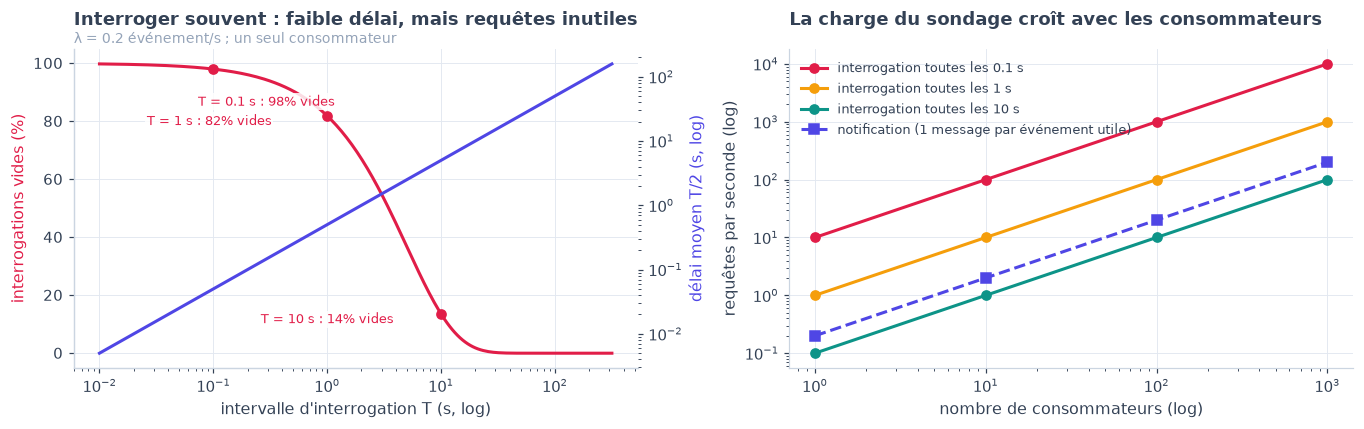

In [2]:
lam = 0.2                                   # 0,2 événement par seconde (12 par minute)
T = np.logspace(-2, 2.5, 200)               # intervalle d'interrogation (s)
vide = np.exp(-lam * T)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12.5, 4))
ax.plot(T, vide * 100, color=ROSE, label="interrogations vides (%)")
ax.set_xscale("log")
ax.set_xlabel("intervalle d'interrogation T (s, log)")
ax.set_ylabel("interrogations vides (%)", color=ROSE)
axb = ax.twinx()
axb.plot(T, T / 2, color=INDIGO, label="délai moyen avant lecture (s)")
axb.set_yscale("log"); axb.set_ylabel("délai moyen T/2 (s, log)", color=INDIGO)
axb.grid(False)
for t0, off in ((0.1, (-10, -24)), (1, (-118, -6)), (10, (-118, -6))):
    ax.plot([t0], [np.exp(-lam * t0) * 100], "o", color=ROSE)
    ax.annotate(f"T = {t0:g} s : {np.exp(-lam * t0):.0%} vides", (t0, np.exp(-lam * t0) * 100),
                off, textcoords="offset points", fontsize=8.5, color=ROSE,
                bbox=dict(fc="white", ec="none", alpha=0.85, pad=1))
ax.set_title("Interroger souvent : faible délai, mais requêtes inutiles")
subtitle(ax, f"λ = {lam} événement/s ; un seul consommateur")

n_cons = np.array([1, 10, 100, 1000])
for T0, c in [(0.1, ROSE), (1.0, AMBER), (10.0, TEAL)]:
    ax2.plot(n_cons, n_cons / T0, "o-", color=c, label=f"interrogation toutes les {T0:g} s")
ax2.plot(n_cons, n_cons * lam, "s--", color=INDIGO, label="notification (1 message par événement utile)")
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("nombre de consommateurs (log)"); ax2.set_ylabel("requêtes par seconde (log)")
ax2.set_title("La charge du sondage croît avec les consommateurs")
ax2.legend(fontsize=8.5, loc="upper left")
plt.tight_layout(); plt.show()

Avec 12 événements par minute, interroger toutes les 100 ms donne un délai moyen de 50 ms
mais 98 % des requêtes sont inutiles ; mille consommateurs envoient alors 10 000 requêtes
par seconde à la base pour récupérer 200 événements utiles. Mieux vaut que les
consommateurs soient **notifiés** quand un événement apparaît. Les bases de données
relationnelles ont des déclencheurs (triggers), mais ils sont limités et n'ont jamais été
pensés comme un mécanisme de diffusion : des outils spécialisés se sont développés pour
cela.

> **À retenir.** Un flux est une suite non bornée d'événements immuables émis par des
> producteurs et lus par des consommateurs. Interroger une base pour les trouver coûte
> d'autant plus cher que l'on veut un délai court ; on préfère un mécanisme de
> notification.